## Tree-Based Models & Ensembles (Telco Churn)

In [ ]:
# Basic data handling
import pandas as pd
import numpy as np


# Train-test split and tuning
from sklearn.model_selection import train_test_split, GridSearchCV

# Preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Models
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Handling imbalance data
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Evaluation
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Save model
import joblib

## 2) Load the Dataset

We use the Telco Customer Churn CSV in the workspace.

In [31]:
# Load dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Quick look at data
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3) Quick Data Check

We check shape, missing values, and target balance.

In [32]:
# Basic dataset information
print("Shape:", df.shape)

# Missing values in each column
print("\nMissing values:")
print(df.isna().sum())

# Target column distribution
print("\nChurn distribution:")
print(df["Churn"].value_counts(normalize=True))

Shape: (7043, 21)

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Churn distribution:
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


## 4) Fix the TotalCharges Data Type Bug

`TotalCharges` has empty strings. We coerce to numeric and then handle NaNs.

In [33]:
# Convert TotalCharges to numeric, forcing bad values to NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check how many NaNs we created
print('TotalCharges NaNs after coercion:', df['TotalCharges'].isna().sum())

TotalCharges NaNs after coercion: 11


## 5) Define Features and Target

We drop the customer ID because it is not useful for prediction.

In [34]:
# Drop ID column (not useful for prediction)
df = df.drop(columns=["customerID"])

# Separate features and target
X = df.drop(columns=["Churn"])

# Convert target into numeric (No = 0, Yes = 1)
y = df["Churn"].map({"No": 0, "Yes": 1})

# Check shapes
print("X shape:", X.shape)
print("y shape:", y.shape)

# Check positive class ratio (churn rate)
print("y positive rate:", y.mean())

X shape: (7043, 19)
y shape: (7043,)
y positive rate: 0.2653698707936959


## 6) Train/Test Split (Prevent Leakage)

We split first, then build the pipeline. This avoids leakage.

In [36]:
# Split data before preprocessing
# This avoids data leakage

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (5634, 19)
Test size: (1409, 19)


## 7) Baseline: Accuracy Trap

A model that predicts **no churn** for everyone can still look good on accuracy.

In [37]:
# Baseline: predict no churn for everyone
y_pred_baseline = np.zeros_like(y_test)

baseline_accuracy = accuracy_score(y_test, y_pred_baseline)
baseline_precision = precision_score(y_test, y_pred_baseline, zero_division=0)
baseline_recall = recall_score(y_test, y_pred_baseline, zero_division=0)
baseline_f1 = f1_score(y_test, y_pred_baseline, zero_division=0)

print("Baseline Accuracy:", baseline_accuracy)
print("Baseline Precision:", baseline_precision)
print("Baseline Recall:", baseline_recall)
print("Baseline F1:", baseline_f1)

Baseline Accuracy: 0.7345635202271115
Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1: 0.0


## 8) Build Preprocessing Pipeline

We handle numeric and categorical columns separately and combine with a ColumnTransformer.

In [39]:

# Separate numeric and categorical columns
num_cols = X.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X.select_dtypes(include=["object", "string"]).columns

# Numeric pipeline 
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline 
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Applying different processing to different columns
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

## 9) Random Forest Pipeline (with SMOTE)

We use `ImbPipeline` so SMOTE only applies to training folds.

In [40]:
# Random Forest pipeline with SMOTE
rf_model = ImbPipeline([
    ("preprocess", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(random_state=42))
])

# Train model
rf_model.fit(X_train, y_train)

,steps,"[('preprocess', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The g

In [41]:
# Predictions
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Metrics
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))
print("AUROC:", roc_auc_score(y_test, rf_prob))

Accuracy: 0.7707594038325053
Precision: 0.571830985915493
Recall: 0.5427807486631016
F1 Score: 0.5569272976680384
AUROC: 0.8148544266191327


In [42]:
"""  
The model performs significantly better than the baseline model.

The baseline model simply predicts all customers as non-churners, achieving an accuracy of 0.73, but it completely fails to identify any actual churn cases (precision, recall, and F1 are all 0.0). This shows that accuracy alone is misleading in this problem due to class imbalance.

In contrast, the Random Forest model achieves a much better balance of performance with an AUROC of approximately 0.81, indicating good ability to separate churn and non-churn customers.

It also improves recall to around 0.54, meaning it correctly identifies more than half of the customers who are likely to churn. However, some churn cases are still missed, which is expected in real-world business settings where perfect recall is difficult.

Overall, the Random Forest model is a strong improvement over the baseline and is useful for targeting at-risk customers, but further improvement is needed to capture more churn cases for better retention strategies.

"""

'  \nThe model performs significantly better than the baseline model.\n\nThe baseline model simply predicts all customers as non-churners, achieving an accuracy of 0.73, but it completely fails to identify any actual churn cases (precision, recall, and F1 are all 0.0). This shows that accuracy alone is misleading in this problem due to class imbalance.\n\nIn contrast, the Random Forest model achieves a much better balance of performance with an AUROC of approximately 0.81, indicating good ability to separate churn and non-churn customers.\n\nIt also improves recall to around 0.54, meaning it correctly identifies more than half of the customers who are likely to churn. However, some churn cases are still missed, which is expected in real-world business settings where perfect recall is difficult.\n\nOverall, the Random Forest model is a strong improvement over the baseline and is useful for targeting at-risk customers, but further improvement is needed to capture more churn cases for bet

In [43]:
# XGBoost model initialize gareko
# XGBoost pipeline

xgb_model = ImbPipeline([
    ("preprocess", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", XGBClassifier(eval_metric="logloss", random_state=42))
])

In [44]:
#hyperparameter tuning

# Parameters for tuning
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 4, 5],
    "model__learning_rate": [0.01, 0.1]
}

# Grid search setup
grid = GridSearchCV(
    xgb_model,
    param_grid,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Train tuning model
grid.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__learning_rate': [0.01, 0.1], 'model__max_depth': [3, 4, ...], 'model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate 

In [45]:
# Best model after tuning
best_model = grid.best_estimator_

print("Best Parameters:", grid.best_params_)
print("Best AUROC:", grid.best_score_)

Best Parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100}
Best AUROC: 0.8457777001581561


In [46]:
#final Evaluation of best model on test set

# Predictions
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

# Metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("AUROC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.7721788502484032
Precision: 0.556989247311828
Recall: 0.6925133689839572
F1: 0.6174016686531585
AUROC: 0.8431088377379937


In [47]:
# Save full pipeline (VERY IMPORTANT)

joblib.dump(best_model, "telco_churn_pipeline_v1.joblib")

['telco_churn_pipeline_v1.joblib']

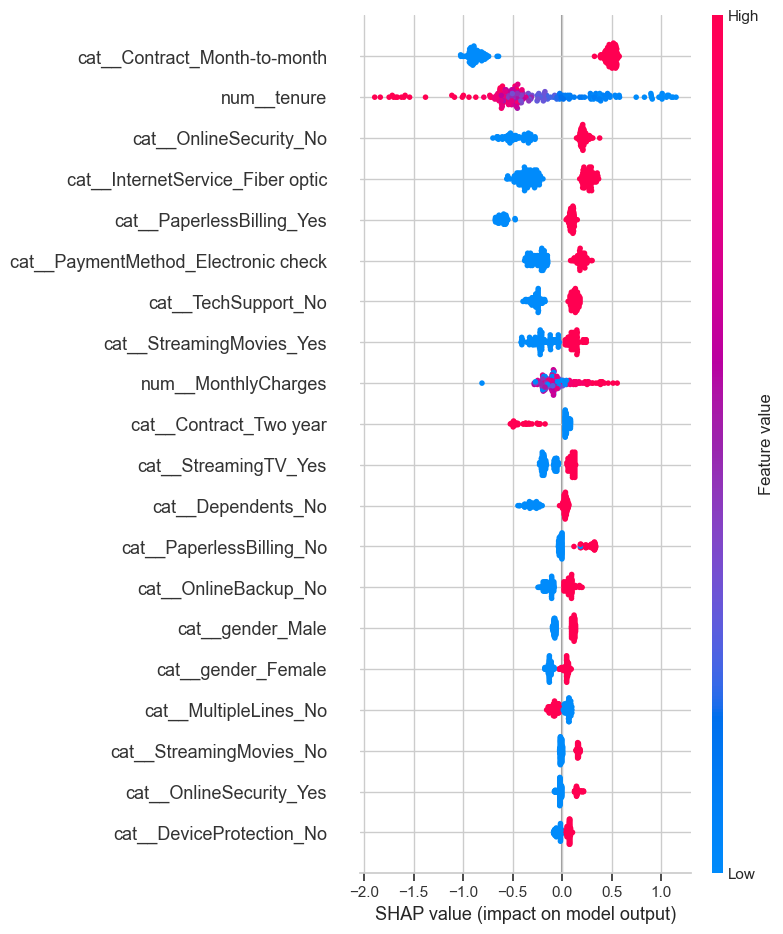

In [48]:
#SHAP explainability for XGBoost model

import shap

# sample data
sample = X_test.sample(200, random_state=42)

# transform data
X_trans = best_model.named_steps["preprocess"].transform(sample)

# model
model = best_model.named_steps["model"]

# SHAP
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_trans)

# feature names
features = best_model.named_steps["preprocess"].get_feature_names_out()

# global plot
shap.summary_plot(shap_values, X_trans, feature_names=features)

# Global SHAP Summary

This plot shows what features are most important in predicting customer churn.

Each dot is one customer.

---

## 1. Feature Importance
- Top features = most important for prediction
- Bottom features = less important

---

## 2. Impact (Left vs Right)
- Right side → increases churn risk (customer likely to leave)
- Left side → decreases churn risk (customer likely to stay)

---

## 3. Color Meaning
- Red = high value (example: high charges, long tenure, “Yes”)
- Blue = low value (example: low charges, short tenure, “No”)

---

## 4. Simple Insight
- New customers (low tenure) → higher churn risk
- Month-to-month contract → higher churn risk
- Long-term customers → more likely to stay

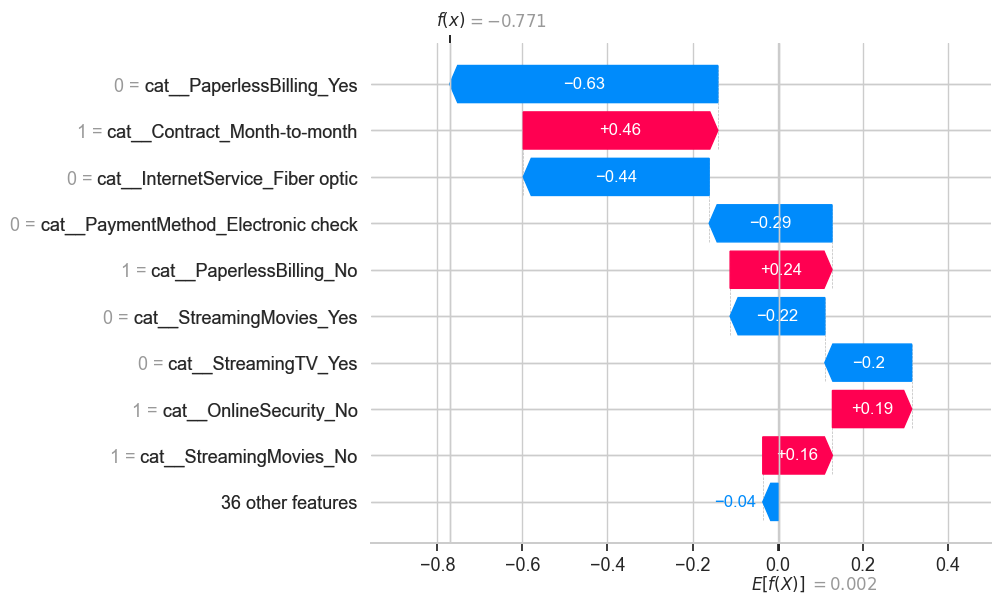

In [49]:
#local SHAP (individual prediction)

# explain one customer
shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[0],
        base_values=explainer.expected_value,
        data=X_trans[0],
        feature_names=features
    )
)

# Local SHAP

This plot explains why the model made a prediction for one specific customer.

It shows how different features increase or decrease the final prediction.

---

## 1. Start and End

- Baseline (E[f(X)]) is the average model score before using any customer information.
- Final score (f(x)) is the final prediction after considering all features, here it is -0.771.

A negative value usually means the customer is more likely to stay.

---

## 2. Blue Bars (Decrease prediction)

These features reduce the churn risk:

- No paperless billing
- No fiber optic internet
- No electronic check payment
- No streaming services

These factors push the prediction toward staying.

---

## 3. Red Bars (Increase prediction)

These features increase churn risk:

- Month-to-month contract
- Other service-related risk indicators

These factors push the prediction toward leaving.

---

## 4. Simple Summary

The model combines all features and balances them.

Even though month-to-month contract increases churn risk, other features reduce it more, so the final prediction suggests the customer is likely to stay.

In [51]:
import json
from datetime import datetime

metadata = {
    "project_name": "Telco Customer Churn Prediction",
    "version": "v1",
    "training_date": str(datetime.now().date()),
    
    "best_model": "XGBoost (Tuned with GridSearchCV)",

    "model_performance": {
        "Random Forest": {
            "accuracy": 0.7707594038325053,
            "precision": 0.571830985915493,
            "recall": 0.5427807486631016,
            "f1": 0.5569272976680384,
            "roc_auc": 0.8148544266191327
        },
        "XGBoost (Tuned)": {
            "accuracy": 0.7721788502484032,
            "precision": 0.556989247311828,
            "recall": 0.6925133689839572,
            "f1": 0.6174016686531585,
            "roc_auc": 0.8431088377379937
        }
    },

    "final_selected_model": "XGBoost (chosen for highest ROC-AUC and recall)",

    "best_hyperparameters": {
        "learning_rate": 0.1,
        "max_depth": 3,
        "n_estimators": 100
    },

    "features_used": "All preprocessed numeric and categorical features from Telco dataset using ColumnTransformer",

    "target_variable": "Churn (0 = No, 1 = Yes)",

    "data_imbalance_handling": "SMOTE applied only on training data inside pipeline",

    "pipeline_design": [
        "ColumnTransformer for preprocessing",
        "SMOTE for imbalance handling",
        "ImbPipeline to avoid data leakage"
    ],

    "key_notes": [
        "XGBoost outperformed Random Forest in ROC-AUC and recall",
        "Higher recall is prioritized to reduce missed churn customers",
        "Model tuned using GridSearchCV with 5-fold cross validation"
    ],

    "business_use_case": "Predict customer churn and support targeted retention strategies such as discounts and contract upgrades",

    "limitations": "Model may still produce false positives and may not generalize well to unseen pricing structures or new customer behavior"
}

# Save file
with open("model_metadata_v1.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("model_metadata_v1.json saved successfully!")

model_metadata_v1.json saved successfully!
